# Import libraries

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import shap

RANDOM_STATE = 42

# Load data

In [ ]:
# Load The Dataset
df = pd.read_csv("/content/Loan_default.csv.zip")

In [ ]:
# First five rows of data
df.head()

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [ ]:
# Shape
df.shape

(255347, 18)

In [ ]:
# Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  object 
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  object 
 11  EmploymentType  255347 non-null  object 
 12  MaritalStatus   255347 non-null  object 
 13  HasMortgage     255347 non-null  object 
 14  HasDependents   255347 non-null  object 
 15  LoanPurpose     255347 non-null  object 
 16  HasCoSigner     255347 non-null  object 
 17  Default   

In [ ]:
# Summary statistics
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
LoanID,255347,255347,ZTH91CGL0B,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,255347.0,NaN,NaN,NaN,43.498306,14.990258,18.0,31.0,43.0,56.0,69.0
Income,255347.0,NaN,NaN,NaN,82499.304597,38963.013729,15000.0,48825.5,82466.0,116219.0,149999.0
LoanAmount,255347.0,NaN,NaN,NaN,127578.865512,70840.706142,5000.0,66156.0,127556.0,188985.0,249999.0
CreditScore,255347.0,NaN,NaN,NaN,574.264346,158.903867,300.0,437.0,574.0,712.0,849.0
MonthsEmployed,255347.0,NaN,NaN,NaN,59.541976,34.643376,0.0,30.0,60.0,90.0,119.0
NumCreditLines,255347.0,NaN,NaN,NaN,2.501036,1.117018,1.0,2.0,2.0,3.0,4.0
InterestRate,255347.0,NaN,NaN,NaN,13.492773,6.636443,2.0,7.77,13.46,19.25,25.0
LoanTerm,255347.0,NaN,NaN,NaN,36.025894,16.96933,12.0,24.0,36.0,48.0,60.0
DTIRatio,255347.0,NaN,NaN,NaN,0.500212,0.230917,0.1,0.3,0.5,0.7,0.9


# Data quality checking

In [ ]:
# Missing Values analysis
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())



Dataset shape: (255347, 18)

Missing values:
LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64


In [ ]:
# Duplicate rows analysis
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [ ]:
# Target distribution
print("\nTarget distribution:")
print(df["Default"].value_counts())


Target distribution:
Default
0    225694
1     29653
Name: count, dtype: int64


In [ ]:
print("\nTarget percentage:")
print(df["Default"].value_counts(normalize=True) * 100)


Target percentage:
Default
0    88.387175
1    11.612825
Name: proportion, dtype: float64


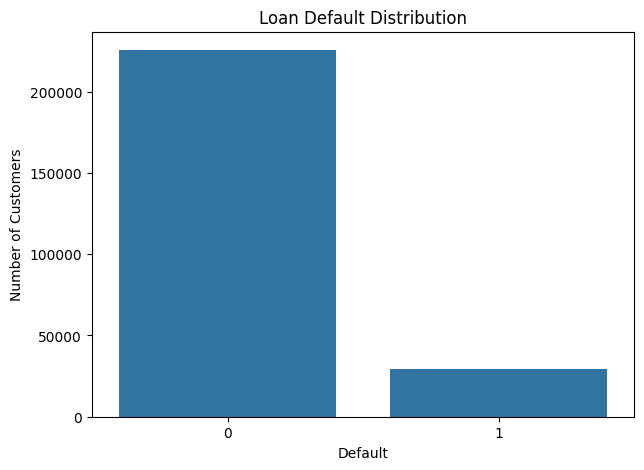

In [ ]:
# Visualise the target distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Default")

plt.title("Loan Default Distribution")
plt.xlabel("Default")
plt.ylabel("Number of Customers")

plt.show()

# Data Preprocessing

In [ ]:
# Remove the LoanID
df = df.drop(columns=["LoanID"])

In [ ]:
#  DOMAIN-BASED FEATURE ENGINEERING

df_fe = df.copy()

# Avoid division by zero
epsilon = 1e-6

#  Loan amount relative to annual income
df_fe["LoanToIncomeRatio"] = (
    df_fe["LoanAmount"] / (df_fe["Income"] + epsilon)
)

# Approximate monthly income
df_fe["MonthlyIncome"] = (
    df_fe["Income"] / 12
)

#  Approximate monthly loan repayment
df_fe["EstimatedMonthlyPayment"] = (
    df_fe["LoanAmount"] / (df_fe["LoanTerm"] + epsilon)
)

#  Estimated repayment burden relative to monthly income
df_fe["PaymentToIncomeRatio"] = (
    df_fe["EstimatedMonthlyPayment"] /
    (df_fe["MonthlyIncome"] + epsilon)
)

#  Interest burden
df_fe["InterestBurden"] = (
    df_fe["LoanAmount"] *
    df_fe["InterestRate"] / 100
)

#  Loan amount adjusted for credit score
df_fe["LoanAmountPerCreditScore"] = (
    df_fe["LoanAmount"] /
    (df_fe["CreditScore"] + epsilon)
)

#  Income adjusted for credit score
df_fe["IncomePerCreditScore"] = (
    df_fe["Income"] /
    (df_fe["CreditScore"] + epsilon)
)

#  Credit-line intensity
df_fe["CreditLinesPerYear"] = (
    df_fe["NumCreditLines"] /
    ((df_fe["Age"] - 18).clip(lower=1))
)

#  Employment stability
df_fe["EmploymentStability"] = (
    df_fe["MonthsEmployed"] /
    ((df_fe["Age"] * 12) + epsilon)
)

#  Loan term in years
df_fe["LoanTermYears"] = (
    df_fe["LoanTerm"] / 12
)

#  Debt-to-income and interest interaction
df_fe["DTI_Interest_Interaction"] = (
    df_fe["DTIRatio"] *
    df_fe["InterestRate"]
)

#  Loan burden and DTI interaction
df_fe["LoanBurden_DTI"] = (
    df_fe["LoanToIncomeRatio"] *
    df_fe["DTIRatio"]
)

#  Credit score and income interaction
df_fe["CreditIncomeInteraction"] = (
    df_fe["CreditScore"] *
    np.log1p(df_fe["Income"])
)

#  Age-income relationship
df_fe["AgeIncomeInteraction"] = (
    df_fe["Age"] *
    np.log1p(df_fe["Income"])
)

print("Feature engineering completed.")
print("New dataset shape:", df_fe.shape)

print("\nNew engineered features:")
new_features = [
    "LoanToIncomeRatio",
    "MonthlyIncome",
    "EstimatedMonthlyPayment",
    "PaymentToIncomeRatio",
    "InterestBurden",
    "LoanAmountPerCreditScore",
    "IncomePerCreditScore",
    "CreditLinesPerYear",
    "EmploymentStability",
    "LoanTermYears",
    "DTI_Interest_Interaction",
    "LoanBurden_DTI",
    "CreditIncomeInteraction",
    "AgeIncomeInteraction"
]

for feature in new_features:
    print("-", feature)

Feature engineering completed.
New dataset shape: (255347, 31)

New engineered features:
- LoanToIncomeRatio
- MonthlyIncome
- EstimatedMonthlyPayment
- PaymentToIncomeRatio
- InterestBurden
- LoanAmountPerCreditScore
- IncomePerCreditScore
- CreditLinesPerYear
- EmploymentStability
- LoanTermYears
- DTI_Interest_Interaction
- LoanBurden_DTI
- CreditIncomeInteraction
- AgeIncomeInteraction


In [ ]:
# Define predictors and target after feature engineering

X = df_fe.drop(columns=["Default"])
y = df_fe["Default"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (255347, 30)
Target: (255347,)


# Identify continuous and categorical variables

In [ ]:
continuous_features = [
    "Age",
    "Income",
    "LoanAmount",
    "CreditScore",
    "MonthsEmployed",
    "NumCreditLines",
    "InterestRate",
    "LoanTerm",
    "DTIRatio",

    # Engineered features
    "LoanToIncomeRatio",
    "MonthlyIncome",
    "EstimatedMonthlyPayment",
    "PaymentToIncomeRatio",
    "InterestBurden",
    "LoanAmountPerCreditScore",
    "IncomePerCreditScore",
    "CreditLinesPerYear",
    "EmploymentStability",
    "LoanTermYears",
    "DTI_Interest_Interaction",
    "LoanBurden_DTI",
    "CreditIncomeInteraction",
    "AgeIncomeInteraction"
]

In [ ]:
# Categorical variables
categorical_features = [
    "Education",
    "EmploymentType",
    "MaritalStatus",
    "HasMortgage",
    "HasDependents",
    "LoanPurpose",
    "HasCoSigner"
]

In [ ]:
# Verify that they exist
print("Continuous features:")
print(continuous_features)

print("\nCategorical features:")
print(categorical_features)

Continuous features:
['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'LoanToIncomeRatio', 'MonthlyIncome', 'EstimatedMonthlyPayment', 'PaymentToIncomeRatio', 'InterestBurden', 'LoanAmountPerCreditScore', 'IncomePerCreditScore', 'CreditLinesPerYear', 'EmploymentStability', 'LoanTermYears', 'DTI_Interest_Interaction', 'LoanBurden_DTI', 'CreditIncomeInteraction', 'AgeIncomeInteraction']

Categorical features:
['Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner']


In [ ]:
# Check the data types
print(X[continuous_features].dtypes)

print("\nCategorical:")
print(X[categorical_features].dtypes)

Age                           int64
Income                        int64
LoanAmount                    int64
CreditScore                   int64
MonthsEmployed                int64
NumCreditLines                int64
InterestRate                float64
LoanTerm                      int64
DTIRatio                    float64
LoanToIncomeRatio           float64
MonthlyIncome               float64
EstimatedMonthlyPayment     float64
PaymentToIncomeRatio        float64
InterestBurden              float64
LoanAmountPerCreditScore    float64
IncomePerCreditScore        float64
CreditLinesPerYear          float64
EmploymentStability         float64
LoanTermYears               float64
DTI_Interest_Interaction    float64
LoanBurden_DTI              float64
CreditIncomeInteraction     float64
AgeIncomeInteraction        float64
dtype: object

Categorical:
Education         object
EmploymentType    object
MaritalStatus     object
HasMortgage       object
HasDependents     object
LoanPurpose       o

# Exploratory Data Analysis

In [ ]:
# Default rate
default_rate = y.mean() * 100

print(f"Default rate: {default_rate:.2f}%")

Default rate: 11.61%


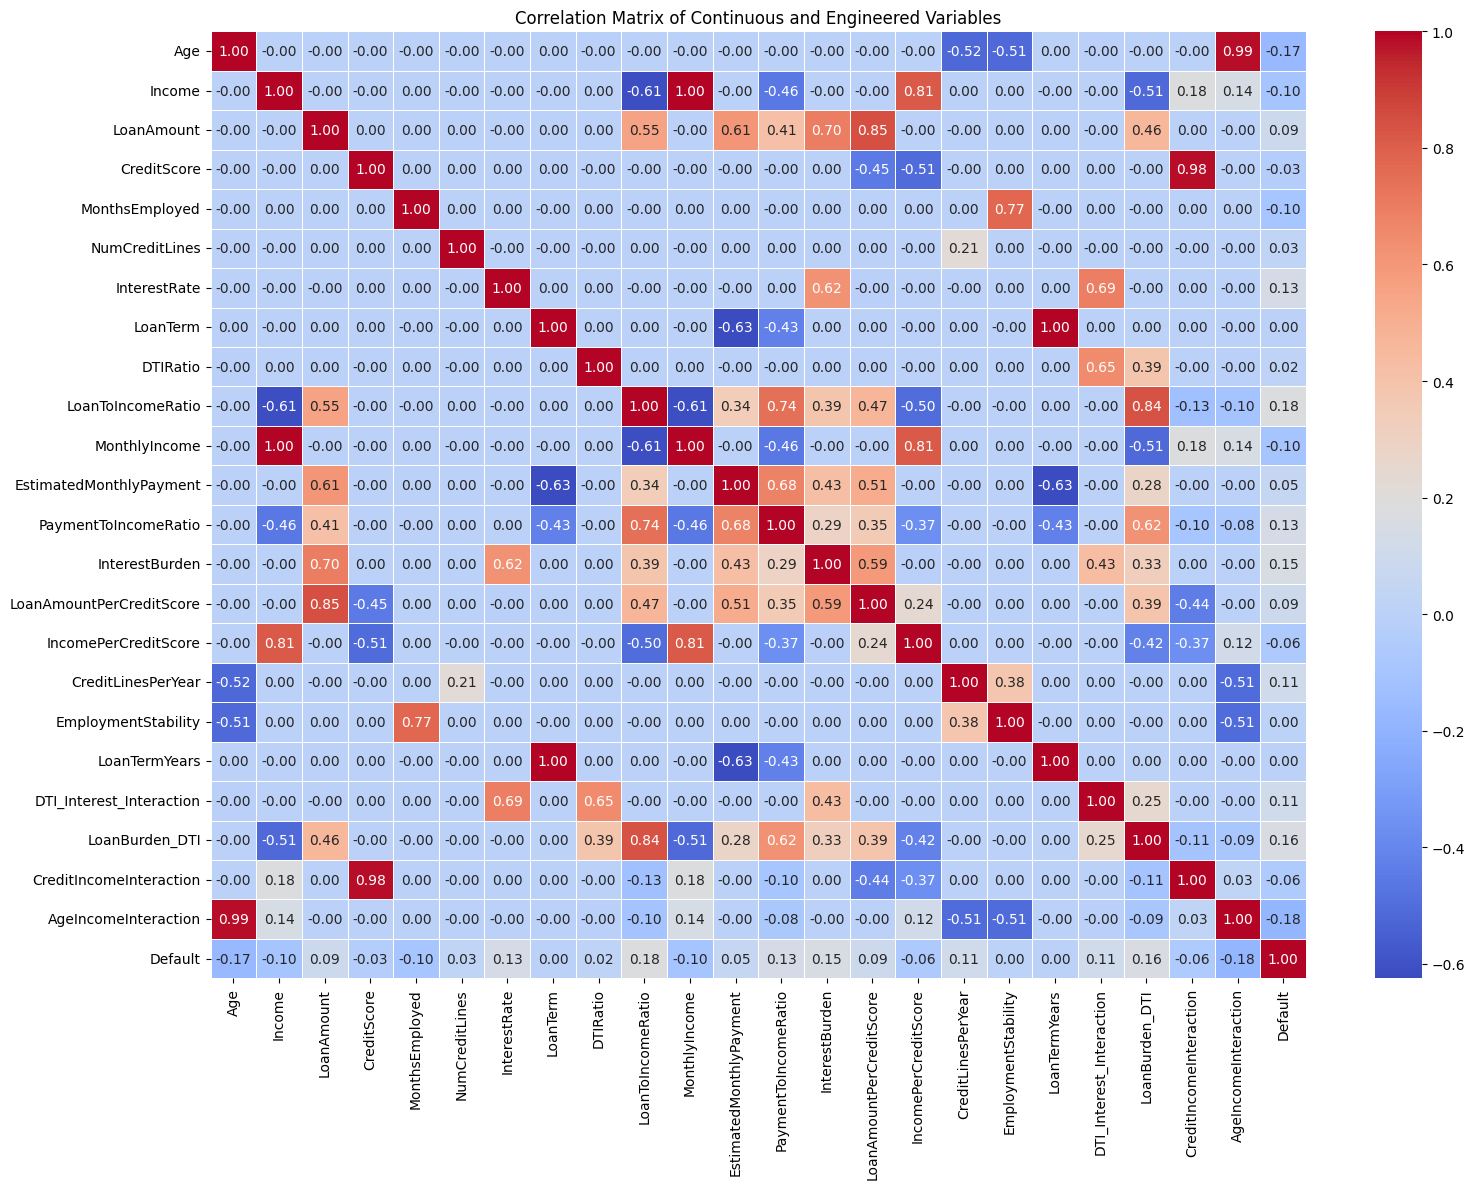

In [ ]:
# Correlation between continuous and engineered variables

plt.figure(figsize=(16, 12))

correlation_features = continuous_features + ["Default"]

sns.heatmap(
    df_fe[correlation_features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Matrix of Continuous and Engineered Variables")
plt.tight_layout()
plt.show()

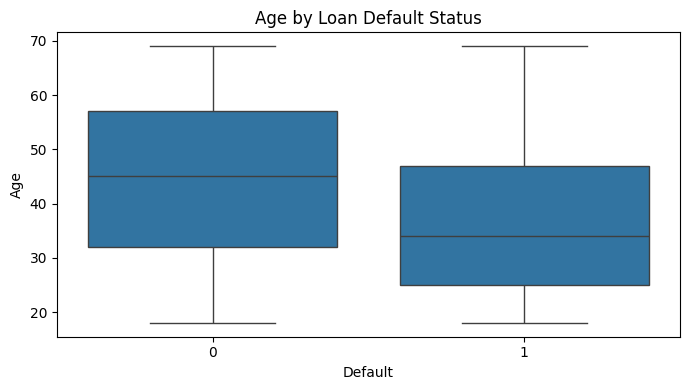

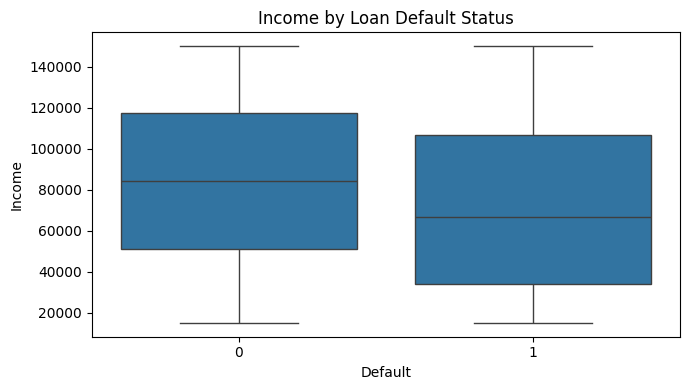

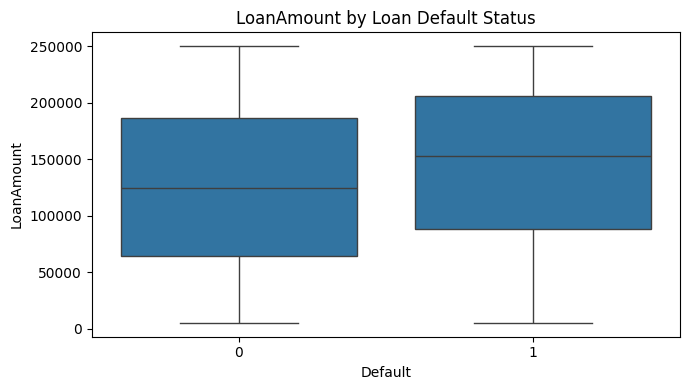

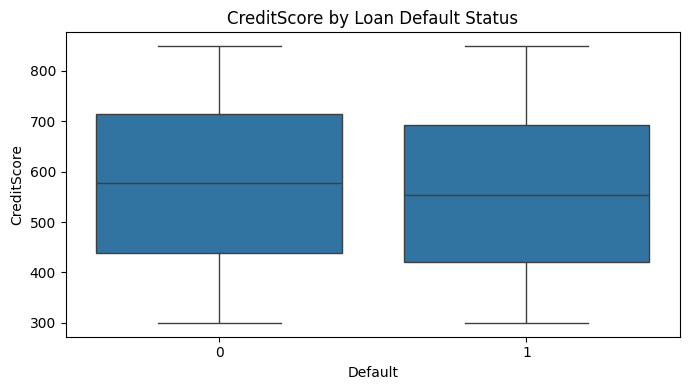

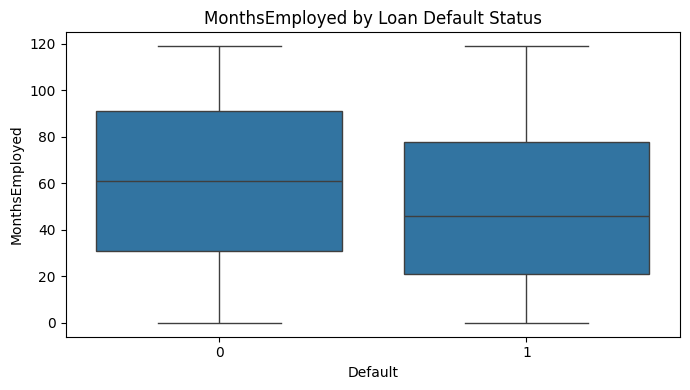

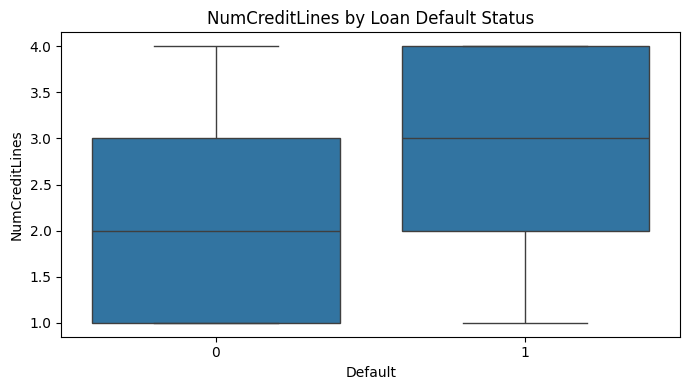

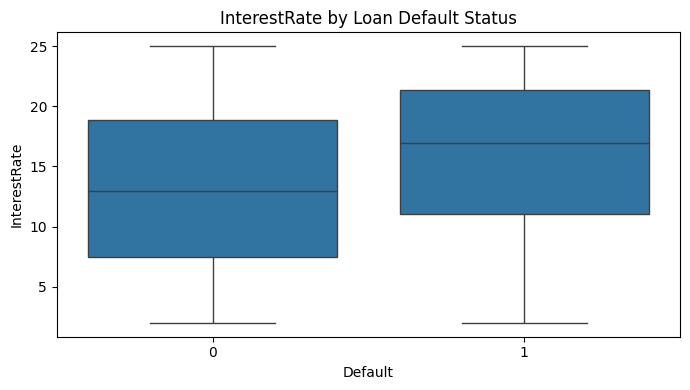

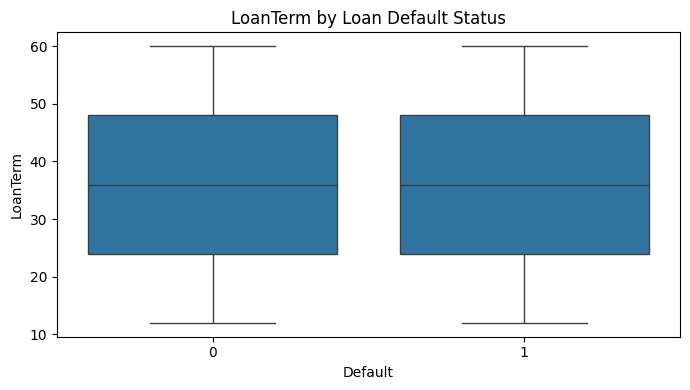

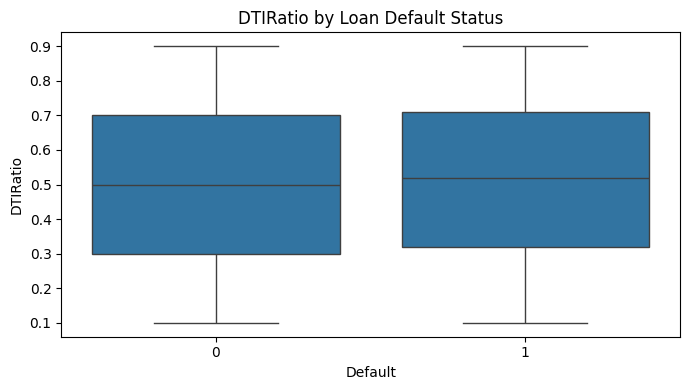

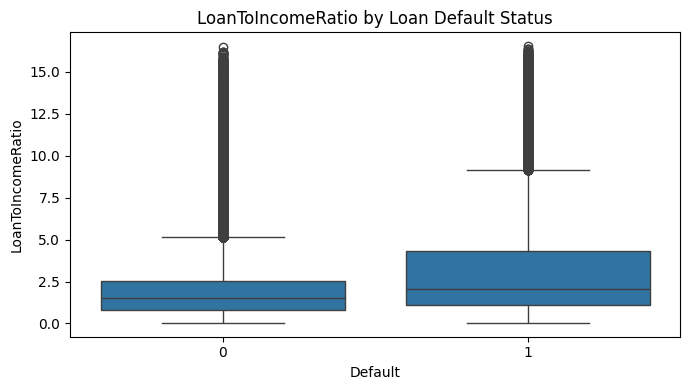

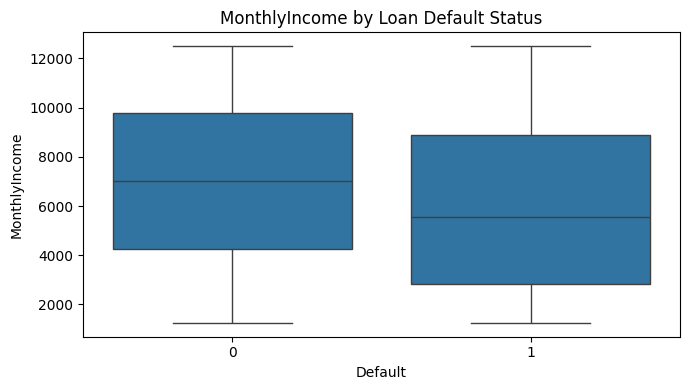

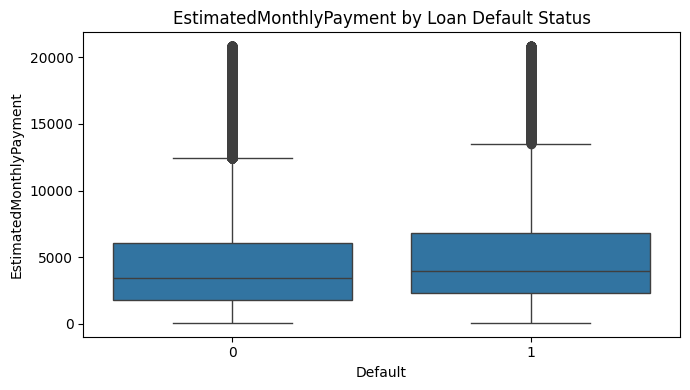

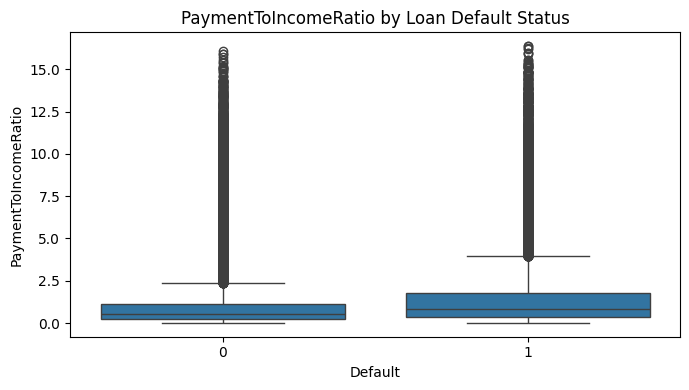

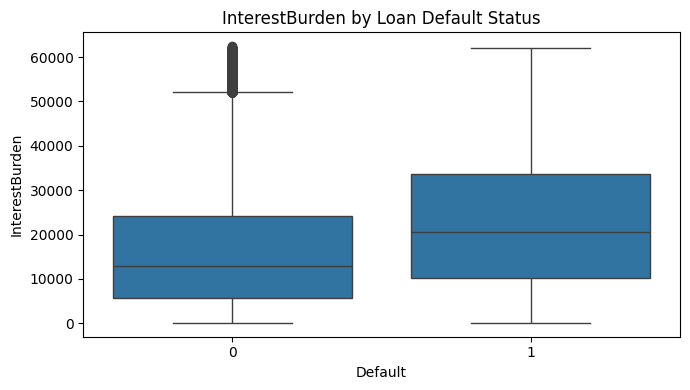

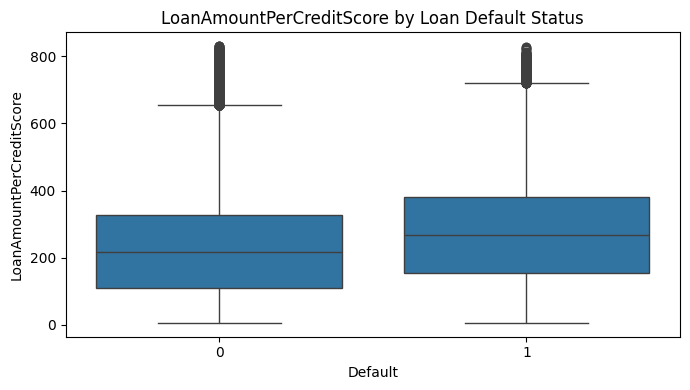

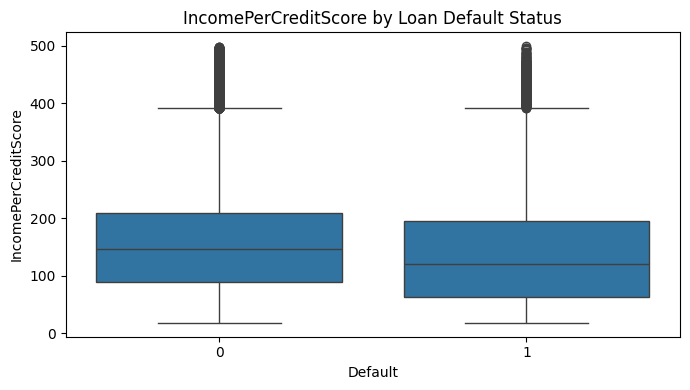

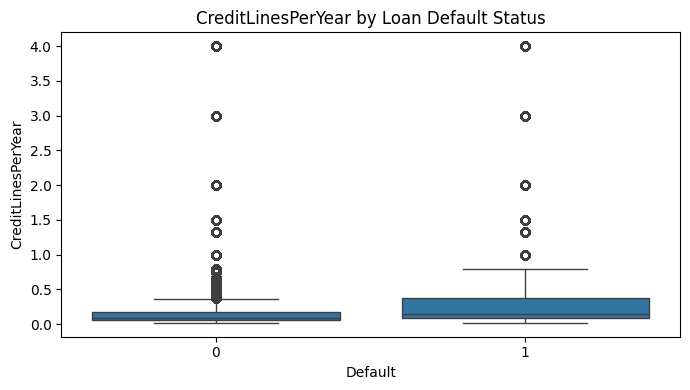

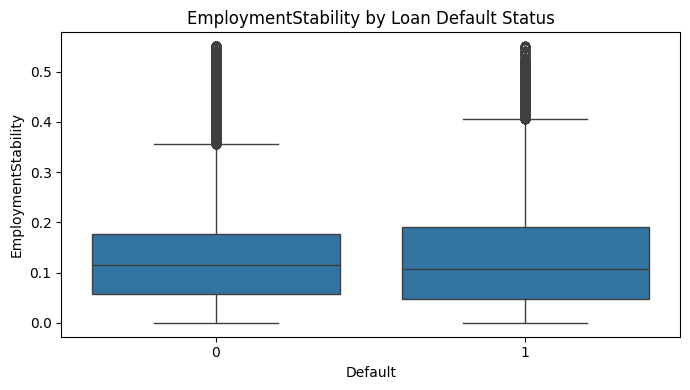

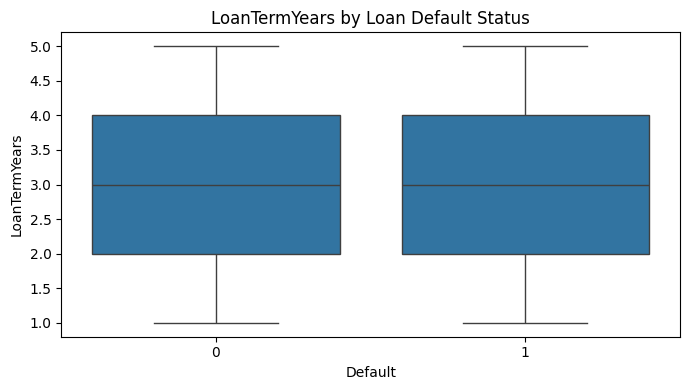

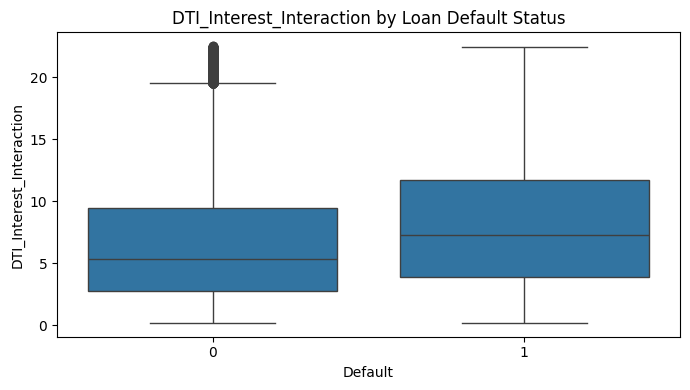

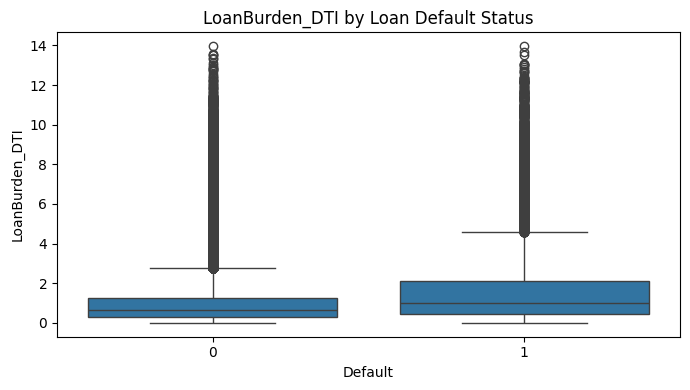

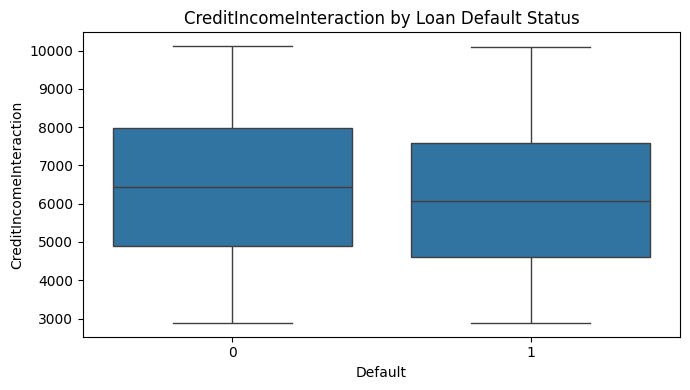

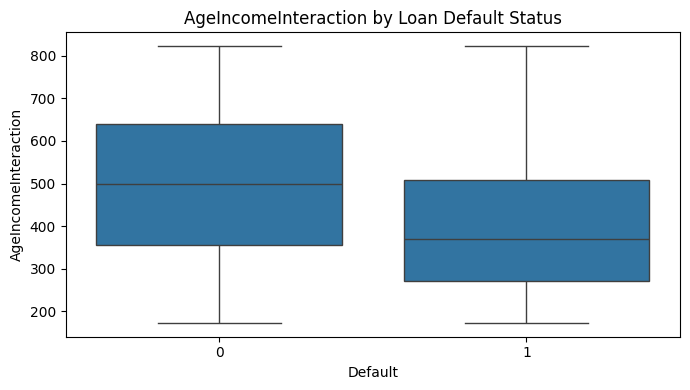

In [ ]:
# Distribution of important continuous variables

for feature in continuous_features:

    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df_fe,
        x="Default",
        y=feature
    )

    plt.title(f"{feature} by Loan Default Status")
    plt.xlabel("Default")
    plt.ylabel(feature)

    plt.tight_layout()
    plt.show()

# Train-test split

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_valid.shape)
print("Testing:", X_test.shape)

print("\nDefault rate:")
print("Training:", y_train.mean())
print("Validation:", y_valid.mean())
print("Testing:", y_test.mean())

Training: (178742, 30)
Validation: (38302, 30)
Testing: (38303, 30)

Default rate:
Training: 0.11612827427241498
Validation: 0.11612970602057333
Testing: 0.1161266741508498


# Preprocessing pipeline

In [ ]:
# Continuous pipeline
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

In [ ]:
# Categorical pipeline
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

In [ ]:
# Combined preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, continuous_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Four machine learning models

In [ ]:
models = {

    "Logistic Regression": LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

In [ ]:
# Combined preprocessing (re-defining preprocessor to ensure it's available)
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, continuous_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [ ]:
# Build complete pipelines (re-building pipelines)
pipelines = {}

for name, model in models.items():

    pipelines[name] = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", model)
        ]
    )

In [ ]:
# Train all four models (re-training models)
trained_models = {}

for name, pipeline in pipelines.items():

    print(f"Training {name}...")

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

print("\nAll models trained successfully.")


All models trained successfully.


In [ ]:
# Re-build complete pipelines (using existing preprocessor and models)
pipelines = {}

for name, model in models.items():

    pipelines[name] = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", model)
        ]
    )

In [ ]:
# Re-train all four models
trained_models = {}

for name, pipeline in pipelines.items():

    print(f"Training {name}...")

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

print("\nAll models re-trained successfully.")

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training XGBoost...

All models re-trained successfully.


In [ ]:
# Re-OPTIMISE DECISION THRESHOLD USING VALIDATION SET
threshold_results = {}

for name, model in trained_models.items():

    valid_prob = model.predict_proba(X_valid)[:, 1]

    thresholds = np.arange(0.10, 0.91, 0.01)

    f1_scores = []

    for threshold in thresholds:

        valid_pred = (
            valid_prob >= threshold
        ).astype(int)

        score = f1_score(
            y_valid,
            valid_pred,
            zero_division=0
        )

        f1_scores.append(score)

    best_index = np.argmax(f1_scores)

    best_threshold = thresholds[best_index]
    best_f1 = f1_scores[best_index]

    threshold_results[name] = {
        "Threshold": best_threshold,
        "Validation F1": best_f1
    }

threshold_df = pd.DataFrame(threshold_results).T

threshold_df = threshold_df.sort_values(
    by="Validation F1",
    ascending=False
)

display(threshold_df)

In [ ]:
# Re-run FINAL TEST SET EVALUATION
results = []

predictions = {}
probabilities = {}

for name, model in trained_models.items():

    test_prob = model.predict_proba(X_test)[:, 1]

    threshold = threshold_results[name]["Threshold"]

    test_pred = (
        test_prob >= threshold
    ).astype(int)

    predictions[name] = test_pred
    probabilities[name] = test_prob

    results.append({
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, test_pred),
        "Precision": precision_score(
            y_test,
            test_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            test_pred,
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_test,
            test_pred,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            test_prob
        )
    })

results_df = pd.DataFrame(results)

# PRIMARY SELECTION CRITERION = F1-SCORE
results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

display(results_df)

In [ ]:
# OPTIMISE DECISION THRESHOLD USING VALIDATION SET (re-calculating threshold_df)
threshold_results = {}

for name, model in trained_models.items():

    valid_prob = model.predict_proba(X_valid)[:, 1]

    thresholds = np.arange(0.10, 0.91, 0.01)

    f1_scores = []

    for threshold in thresholds:

        valid_pred = (
            valid_prob >= threshold
        ).astype(int)

        score = f1_score(
            y_valid,
            valid_pred,
            zero_division=0
        )

        f1_scores.append(score)

    best_index = np.argmax(f1_scores)

    best_threshold = thresholds[best_index]
    best_f1 = f1_scores[best_index]

    threshold_results[name] = {
        "Threshold": best_threshold,
        "Validation F1": best_f1
    }

threshold_df = pd.DataFrame(threshold_results).T

threshold_df = threshold_df.sort_values(
    by="Validation F1",
    ascending=False
)

display(threshold_df)

,Threshold,Validation F1
Logistic Regression,0.62,0.370945
XGBoost,0.61,0.370096
Random Forest,0.55,0.357130
Decision Tree,0.68,0.328113


In [ ]:
# FINAL TEST SET EVALUATION (re-evaluating and populating results_df)
results = []

predictions = {}
probabilities = {}

for name, model in trained_models.items():

    test_prob = model.predict_proba(X_test)[:, 1]

    threshold = threshold_results[name]["Threshold"]

    test_pred = (
        test_prob >= threshold
    ).astype(int)

    predictions[name] = test_pred
    probabilities[name] = test_prob

    results.append({
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, test_pred),
        "Precision": precision_score(
            y_test,
            test_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            test_pred,
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_test,
            test_pred,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            test_prob
        )
    })

results_df = pd.DataFrame(results)

# PRIMARY SELECTION CRITERION = F1-SCORE
results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

display(results_df)

,Model,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.62,0.804950,0.302392,0.520009,0.382409,0.765775
1,XGBoost,0.61,0.800459,0.294798,0.515962,0.375215,0.760575
2,Random Forest,0.55,0.817456,0.302177,0.436826,0.357235,0.752052
3,Decision Tree,0.68,0.815837,0.282543,0.380621,0.324330,0.702177


In [ ]:
# Build complete pipelines
pipelines = {}

for name, model in models.items():

    pipelines[name] = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", model)
        ]
    )

# Train all four models

In [ ]:
trained_models = {}

for name, pipeline in pipelines.items():

    print(f"Training {name}...")

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

print("\nAll models trained successfully.")

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training XGBoost...

All models trained successfully.


In [ ]:
#  OPTIMISE DECISION THRESHOLD USING VALIDATION SET
threshold_results = {}

for name, model in trained_models.items():

    valid_prob = model.predict_proba(X_valid)[:, 1]

    thresholds = np.arange(0.10, 0.91, 0.01)

    f1_scores = []

    for threshold in thresholds:

        valid_pred = (
            valid_prob >= threshold
        ).astype(int)

        score = f1_score(
            y_valid,
            valid_pred,
            zero_division=0
        )

        f1_scores.append(score)

    best_index = np.argmax(f1_scores)

    best_threshold = thresholds[best_index]
    best_f1 = f1_scores[best_index]

    threshold_results[name] = {
        "Threshold": best_threshold,
        "Validation F1": best_f1
    }

threshold_df = pd.DataFrame(threshold_results).T

threshold_df = threshold_df.sort_values(
    by="Validation F1",
    ascending=False
)

threshold_df

,Threshold,Validation F1
Logistic Regression,0.62,0.370945
XGBoost,0.61,0.370096
Random Forest,0.55,0.357130
Decision Tree,0.68,0.328113


# Generate predictions

In [ ]:
# FINAL TEST SET EVALUATION
results = []

predictions = {}
probabilities = {}

for name, model in trained_models.items():

    test_prob = model.predict_proba(X_test)[:, 1]

    threshold = threshold_results[name]["Threshold"]

    test_pred = (
        test_prob >= threshold
    ).astype(int)

    predictions[name] = test_pred
    probabilities[name] = test_prob

    results.append({
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, test_pred),
        "Precision": precision_score(
            y_test,
            test_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            test_pred,
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_test,
            test_pred,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            test_prob
        )
    })

results_df = pd.DataFrame(results)

# PRIMARY SELECTION CRITERION = F1-SCORE
results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

results_df

,Model,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.62,0.804950,0.302392,0.520009,0.382409,0.765775
1,XGBoost,0.61,0.800459,0.294798,0.515962,0.375215,0.760575
2,Random Forest,0.55,0.817456,0.302177,0.436826,0.357235,0.752052
3,Decision Tree,0.68,0.815837,0.282543,0.380621,0.324330,0.702177


# Model Evaluation

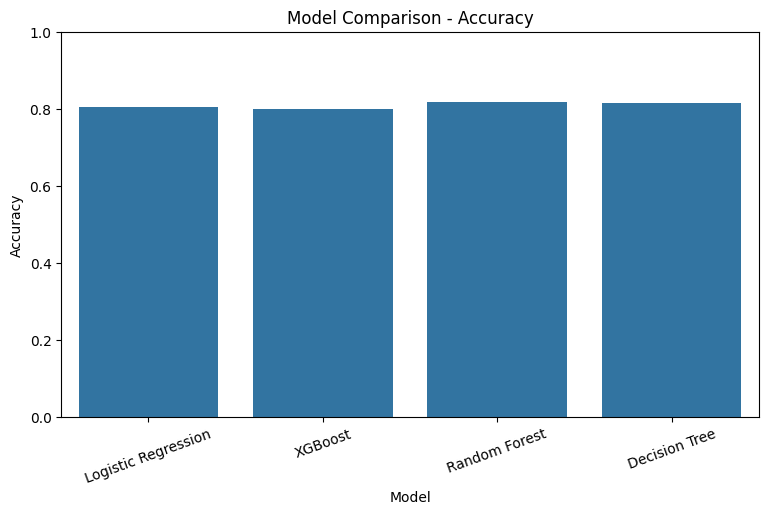

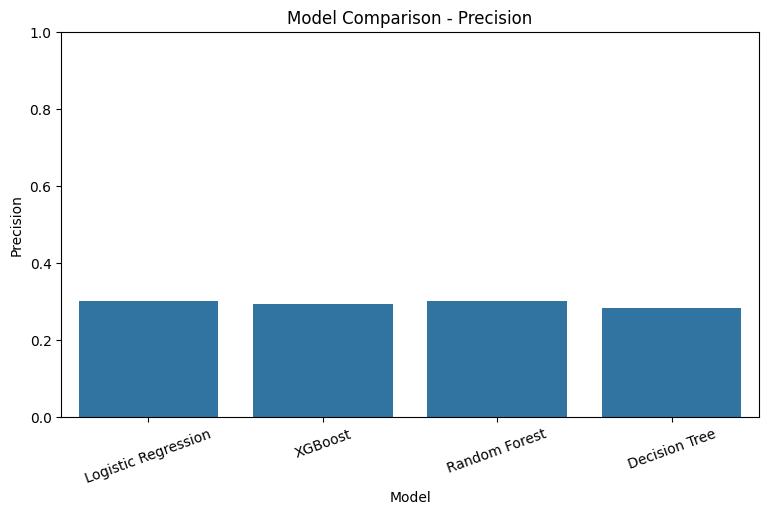

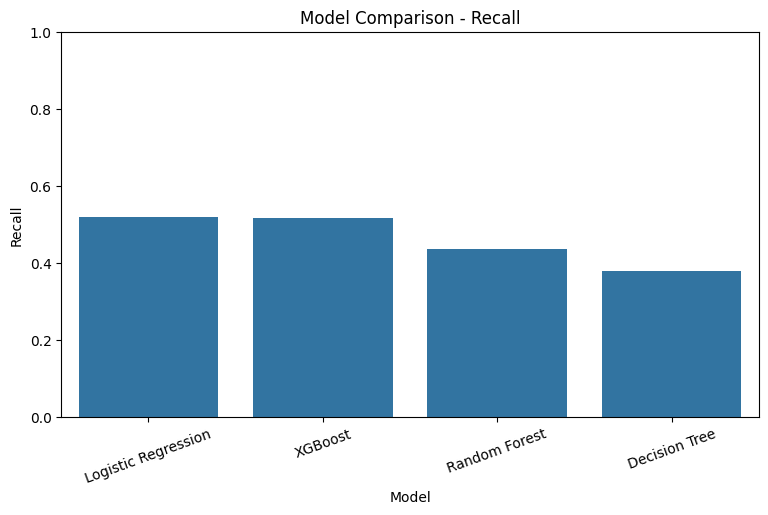

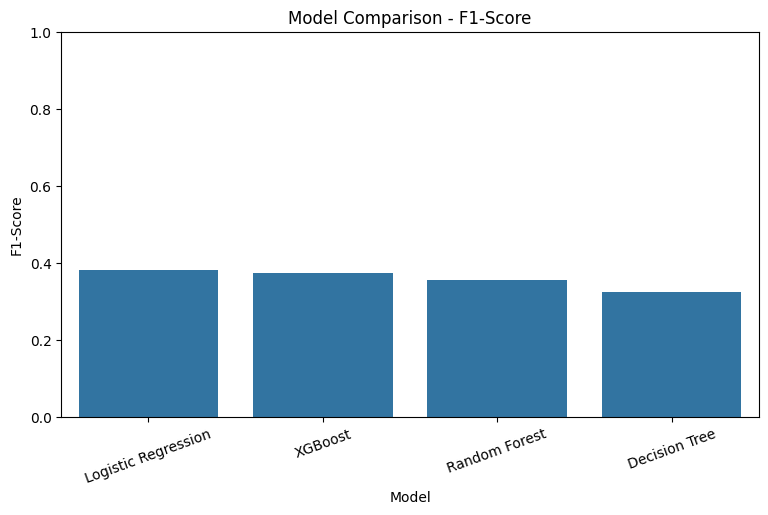

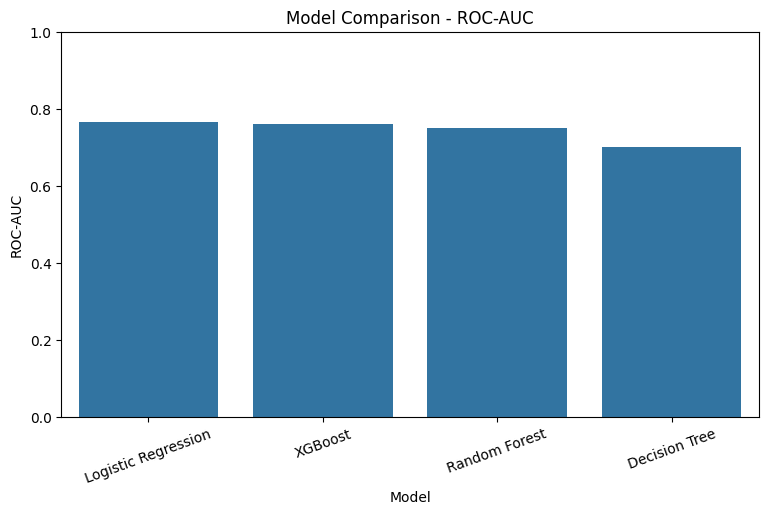

In [ ]:
# Visual model comparison
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

for metric in metrics:

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric
    )

    plt.title(f"Model Comparison - {metric}")
    plt.xticks(rotation=20)
    plt.ylim(0, 1)

    plt.show()

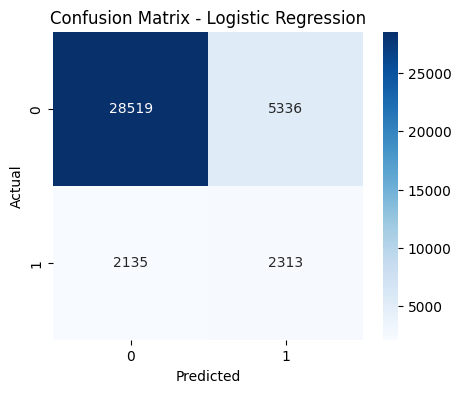

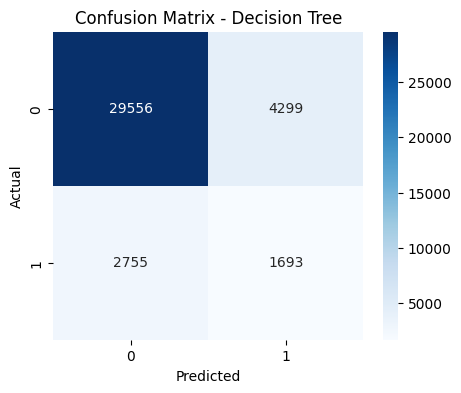

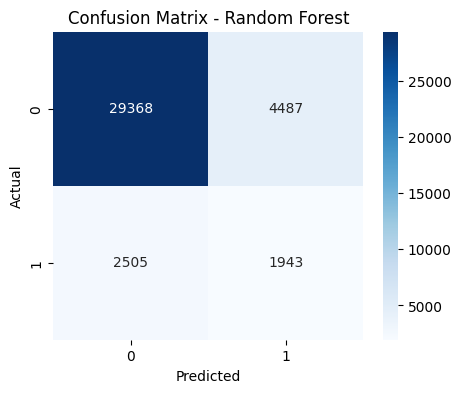

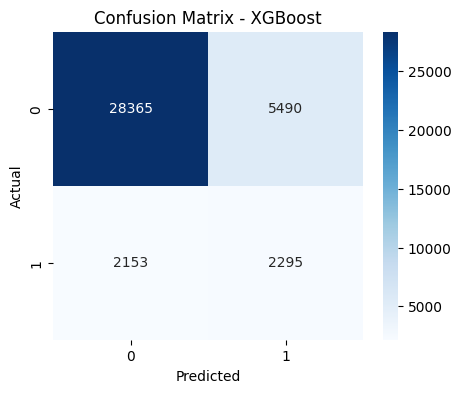

In [ ]:
# Confusion matrices
for name, y_pred in predictions.items():

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()

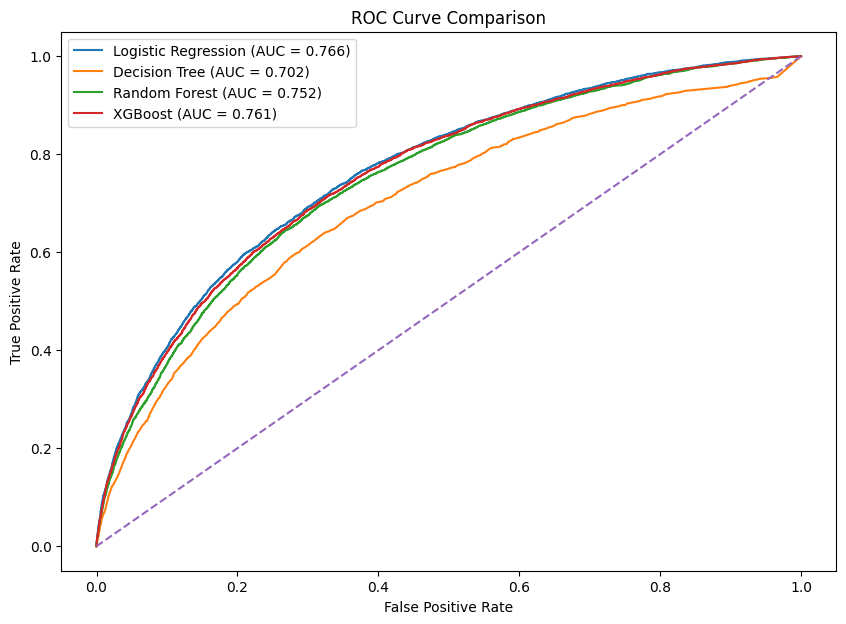

In [ ]:
# ROC curves
plt.figure(figsize=(10, 7))

for name, y_prob in probabilities.items():

    fpr, tpr, _ = roc_curve(y_test, y_prob)

    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()

plt.show()

In [ ]:
# Detailed classification reports
for name, y_pred in predictions.items():

    print("=" * 70)
    print(name)
    print("=" * 70)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["Non-Default", "Default"],
            zero_division=0
        )
    )

Logistic Regression
              precision    recall  f1-score   support

 Non-Default       0.93      0.84      0.88     33855
     Default       0.30      0.52      0.38      4448

    accuracy                           0.80     38303
   macro avg       0.62      0.68      0.63     38303
weighted avg       0.86      0.80      0.83     38303

Decision Tree
              precision    recall  f1-score   support

 Non-Default       0.91      0.87      0.89     33855
     Default       0.28      0.38      0.32      4448

    accuracy                           0.82     38303
   macro avg       0.60      0.63      0.61     38303
weighted avg       0.84      0.82      0.83     38303

Random Forest
              precision    recall  f1-score   support

 Non-Default       0.92      0.87      0.89     33855
     Default       0.30      0.44      0.36      4448

    accuracy                           0.82     38303
   macro avg       0.61      0.65      0.63     38303
weighted avg       0.85   

# Select the best model

In [ ]:

best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

best_threshold = results_df.iloc[0]["Threshold"]

print("=" * 60)
print("MODEL SELECTION")
print("=" * 60)

print("Primary metric: F1-Score")
print("Best model:", best_model_name)
print(f"Optimal threshold: {best_threshold:.2f}")
print(
    f"Test F1-score: "
    f"{results_df.iloc[0]['F1-Score']:.4f}"
)
print(
    f"Test Precision: "
    f"{results_df.iloc[0]['Precision']:.4f}"
)
print(
    f"Test Recall: "
    f"{results_df.iloc[0]['Recall']:.4f}"
)

MODEL SELECTION
Primary metric: F1-Score
Best model: Logistic Regression
Optimal threshold: 0.62
Test F1-score: 0.3824
Test Precision: 0.3024
Test Recall: 0.5200


In [ ]:
best_model = trained_models[best_model_name]

# SHAP Explainability

In [ ]:
#  SELECT BEST MODEL BASED ON F1-SCORE
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_threshold = results_df.iloc[0]["Threshold"]

print("Best model:", best_model_name)
print("Optimal threshold:", best_threshold)
print("Test F1-score:", results_df.iloc[0]["F1-Score"])

Best model: Logistic Regression
Optimal threshold: 0.6199999999999998
Test F1-score: 0.38240886170124827


In [ ]:
# Extract preprocessing and classifier
preprocessor = best_model.named_steps["preprocessor"]
classifier = best_model.named_steps["classifier"]

# Transform test data
X_test_transformed = preprocessor.transform(X_test)

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Convert to dense array if required
if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

print("Transformed test shape:", X_test_transformed.shape)
print("Number of feature names:", len(feature_names))

Transformed test shape: (38303, 45)
Number of feature names: 45


In [ ]:
# Create the SHAP explainer

if best_model_name in ["Random Forest", "Decision Tree", "XGBoost"]:

    explainer = shap.TreeExplainer(classifier)
    shap_values = explainer.shap_values(X_test_transformed)

else:

    explainer = shap.LinearExplainer(
        classifier,
        X_test_transformed
    )

    shap_values = explainer.shap_values(
        X_test_transformed
    )


In [ ]:
# Handle different SHAP output formats

if isinstance(shap_values, list):
    shap_default = shap_values[1]
else:
    shap_default = shap_values

print("SHAP shape:", np.array(shap_default).shape)

SHAP shape: (38303, 45)


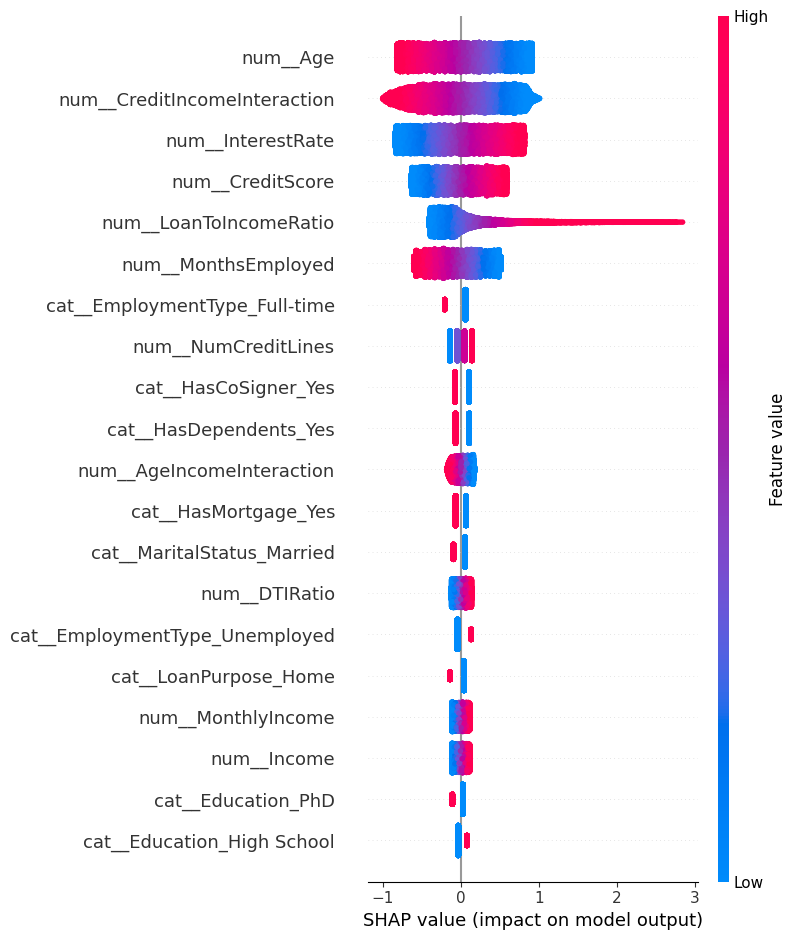

In [ ]:
#  Summary Plot
shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names
)

In [ ]:
# SHAP feature importance
shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": np.abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

shap_importance.head(20)

,Feature,Mean_Absolute_SHAP
0,num__Age,0.440856
1,num__CreditIncomeInteraction,0.434205
2,num__InterestRate,0.415358
3,num__CreditScore,0.307458
4,num__LoanToIncomeRatio,0.292600
5,num__MonthsEmployed,0.282678
6,cat__EmploymentType_Full-time,0.096855
7,num__NumCreditLines,0.093791
8,cat__HasCoSigner_Yes,0.089715
9,cat__HasDependents_Yes,0.087893


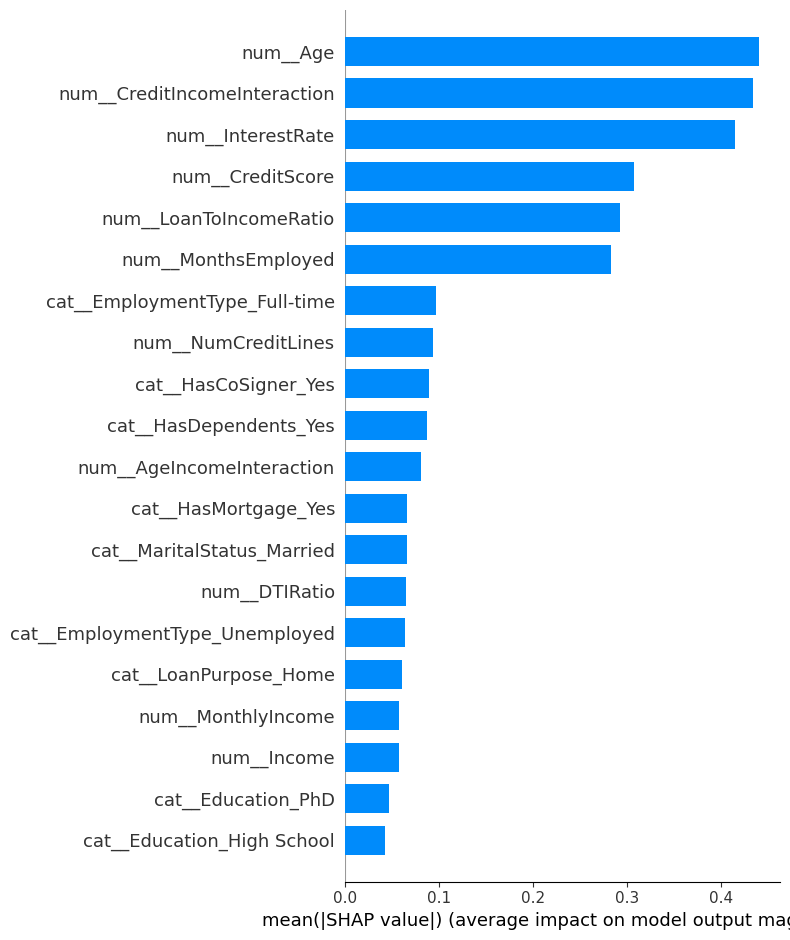

In [ ]:
# GLOBAL SHAP FEATURE IMPORTANCE
shap.summary_plot(
    shap_default,
    X_test_transformed,
    feature_names=feature_names,
    plot_type="bar"
)

# Continuous-variable SHAP analysis

In [ ]:
# Define the continuous variables
continuous_features = [
    "Age",
    "Income",
    "LoanAmount",
    "CreditScore",
    "MonthsEmployed",
    "NumCreditLines",
    "InterestRate",
    "LoanTerm",
    "DTIRatio",

    # Engineered features
    "LoanToIncomeRatio",
    "MonthlyIncome",
    "EstimatedMonthlyPayment",
    "PaymentToIncomeRatio",
    "InterestBurden",
    "LoanAmountPerCreditScore",
    "IncomePerCreditScore",
    "CreditLinesPerYear",
    "EmploymentStability",
    "LoanTermYears",
    "DTI_Interest_Interaction",
    "LoanBurden_DTI",
    "CreditIncomeInteraction",
    "AgeIncomeInteraction"
]

In [ ]:
# Check how they appear after preprocessing
continuous_shap_features = [
    f"num__{feature}"
    for feature in continuous_features
]

print(continuous_shap_features)

['num__Age', 'num__Income', 'num__LoanAmount', 'num__CreditScore', 'num__MonthsEmployed', 'num__NumCreditLines', 'num__InterestRate', 'num__LoanTerm', 'num__DTIRatio', 'num__LoanToIncomeRatio', 'num__MonthlyIncome', 'num__EstimatedMonthlyPayment', 'num__PaymentToIncomeRatio', 'num__InterestBurden', 'num__LoanAmountPerCreditScore', 'num__IncomePerCreditScore', 'num__CreditLinesPerYear', 'num__EmploymentStability', 'num__LoanTermYears', 'num__DTI_Interest_Interaction', 'num__LoanBurden_DTI', 'num__CreditIncomeInteraction', 'num__AgeIncomeInteraction']


In [ ]:
# Find their SHAP column positions
continuous_feature_indices = {}

for feature in continuous_shap_features:
    if feature in feature_names:
        continuous_feature_indices[feature] = list(feature_names).index(feature)

continuous_feature_indices

{'num__Age': 0,
 'num__Income': 1,
 'num__LoanAmount': 2,
 'num__CreditScore': 3,
 'num__MonthsEmployed': 4,
 'num__NumCreditLines': 5,
 'num__InterestRate': 6,
 'num__LoanTerm': 7,
 'num__DTIRatio': 8,
 'num__LoanToIncomeRatio': 9,
 'num__MonthlyIncome': 10,
 'num__EstimatedMonthlyPayment': 11,
 'num__PaymentToIncomeRatio': 12,
 'num__InterestBurden': 13,
 'num__LoanAmountPerCreditScore': 14,
 'num__IncomePerCreditScore': 15,
 'num__CreditLinesPerYear': 16,
 'num__EmploymentStability': 17,
 'num__LoanTermYears': 18,
 'num__DTI_Interest_Interaction': 19,
 'num__LoanBurden_DTI': 20,
 'num__CreditIncomeInteraction': 21,
 'num__AgeIncomeInteraction': 22}

In [ ]:
# Create the continuous-variable SHAP importance table
continuous_shap_results = []

for original_feature in continuous_features:

    transformed_feature = f"num__{original_feature}"

    if transformed_feature in feature_names:

        index = list(feature_names).index(
            transformed_feature
        )

        mean_abs_shap = np.abs(
            shap_values[:, index]
        ).mean()

        continuous_shap_results.append({
            "Continuous Variable": original_feature,
            "Mean Absolute SHAP": mean_abs_shap
        })

continuous_shap_df = pd.DataFrame(
    continuous_shap_results
).sort_values(
    by="Mean Absolute SHAP",
    ascending=False
).reset_index(drop=True)

continuous_shap_df

,Continuous Variable,Mean Absolute SHAP
0,Age,0.440856
1,CreditIncomeInteraction,0.434205
2,InterestRate,0.415358
3,CreditScore,0.307458
4,LoanToIncomeRatio,0.292600
5,MonthsEmployed,0.282678
6,NumCreditLines,0.093791
7,AgeIncomeInteraction,0.081014
8,DTIRatio,0.064897
9,MonthlyIncome,0.057710


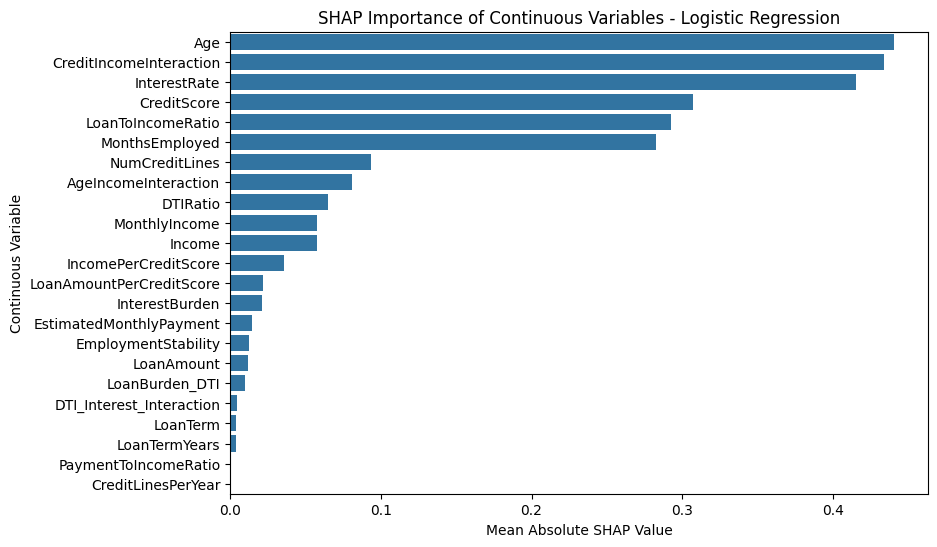

In [ ]:
# Plot the continuous-variable importance
plt.figure(figsize=(9, 6))

sns.barplot(
    data=continuous_shap_df,
    x="Mean Absolute SHAP",
    y="Continuous Variable"
)

plt.title(
    f"SHAP Importance of Continuous Variables - {best_model_name}"
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Continuous Variable")

plt.show()

# Analyse the relationship between the actual value and SHAP value

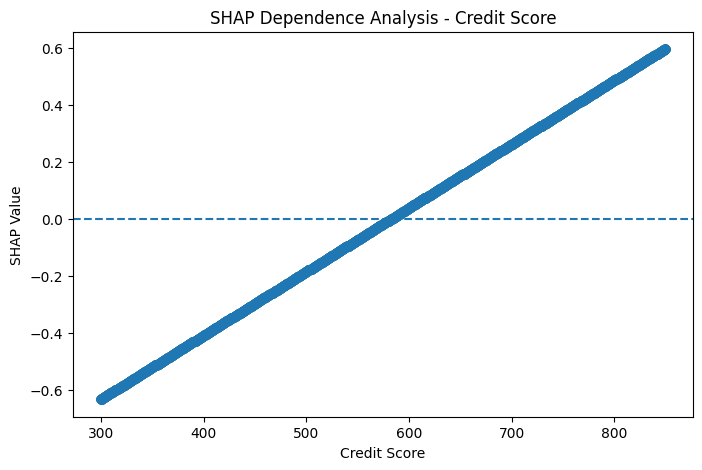

In [ ]:
credit_index = list(feature_names).index(
    "num__CreditScore"
)

plt.figure(figsize=(8, 5))

plt.scatter(
    X_test["CreditScore"],
    shap_values[:, credit_index],
    alpha=0.5
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Credit Score")
plt.ylabel("SHAP Value")
plt.title(
    "SHAP Dependence Analysis - Credit Score"
)

plt.show()

# Automate this for all 9 continuous variables

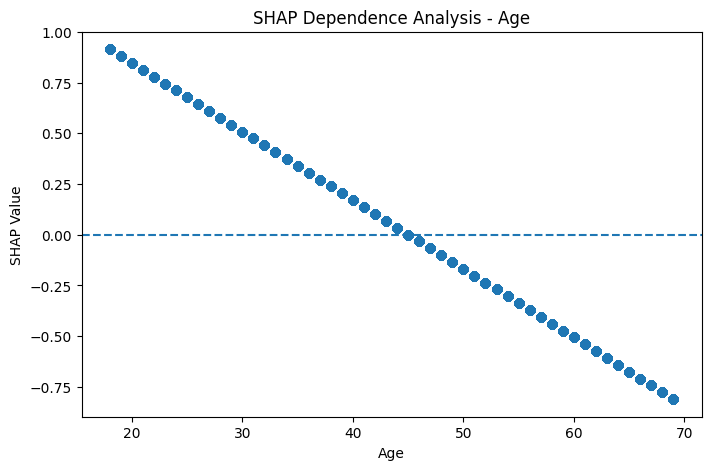

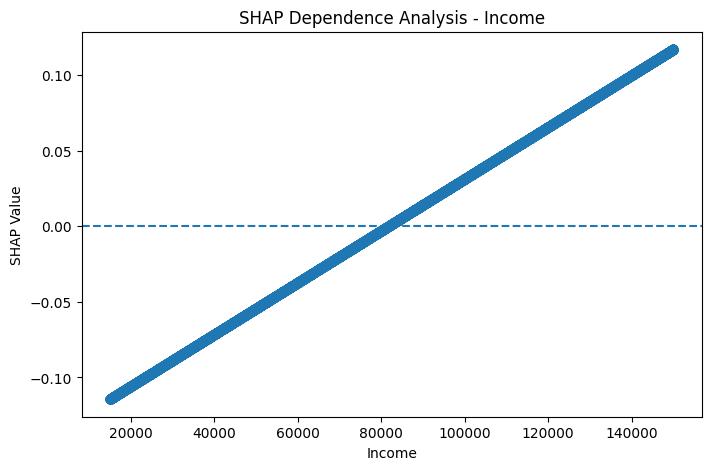

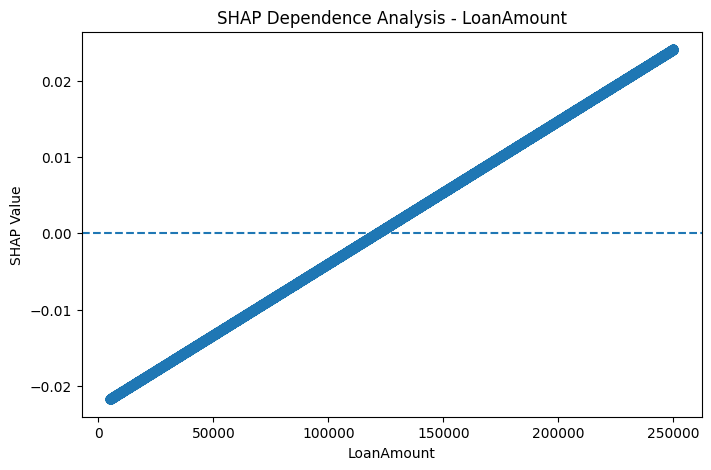

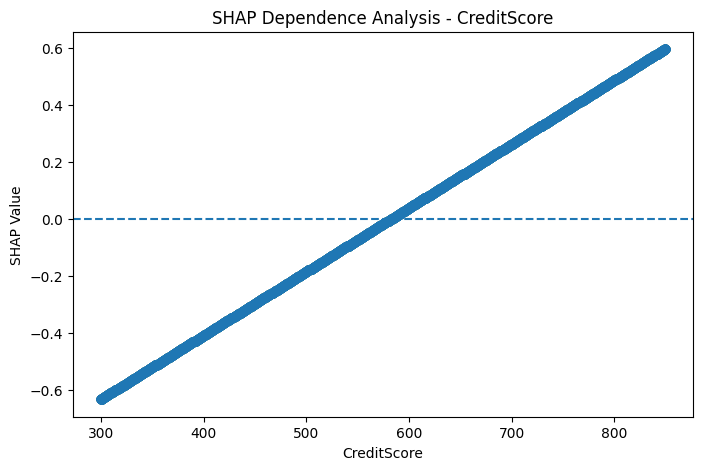

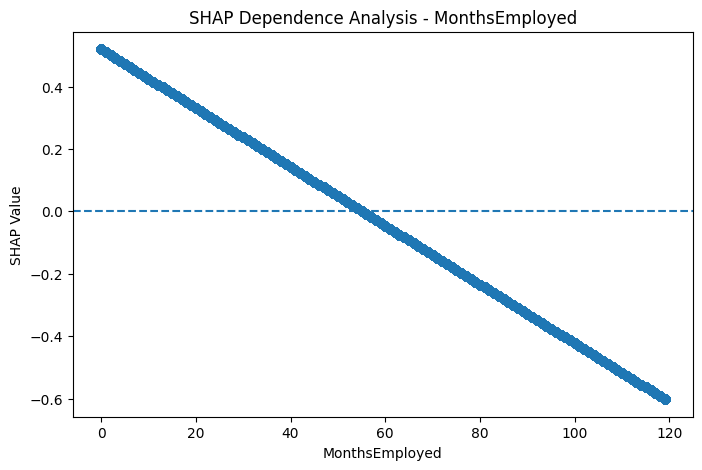

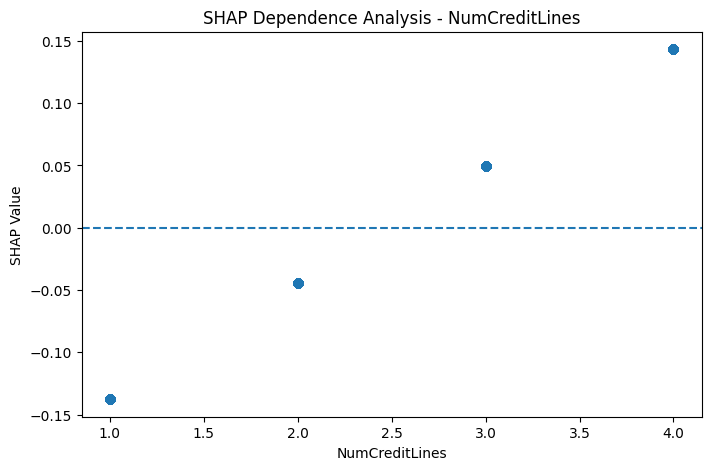

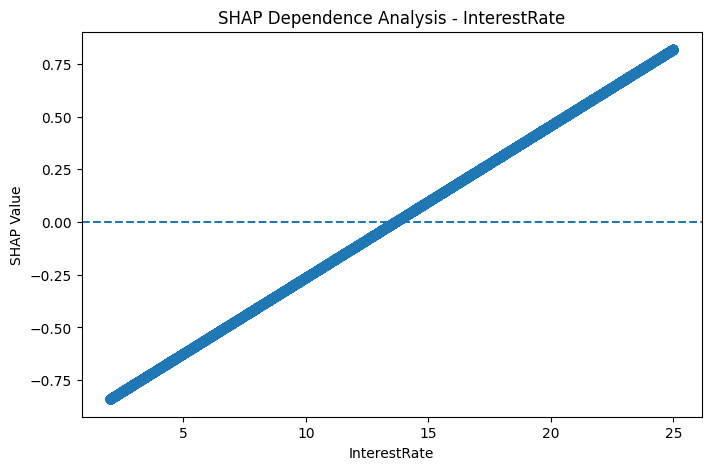

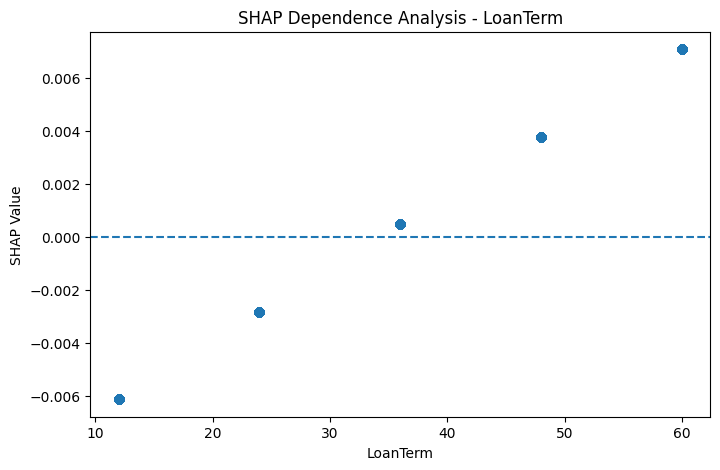

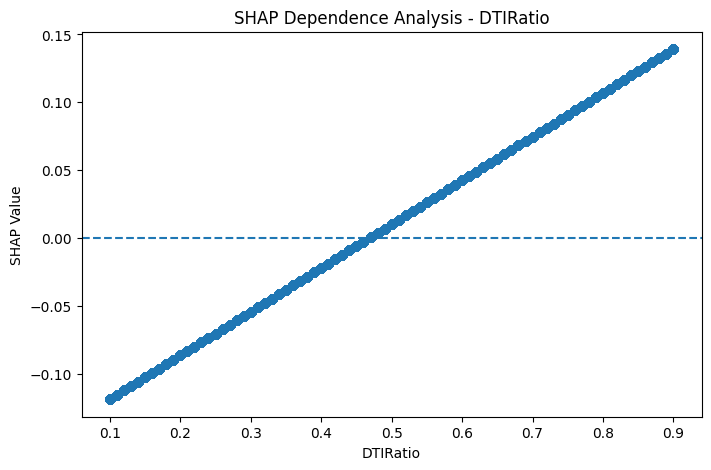

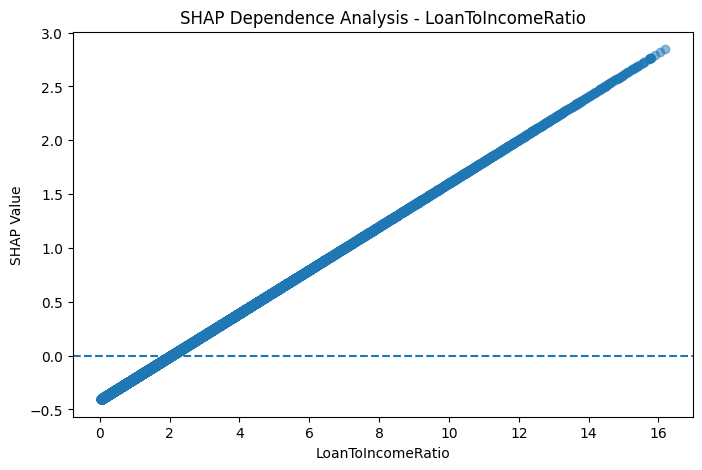

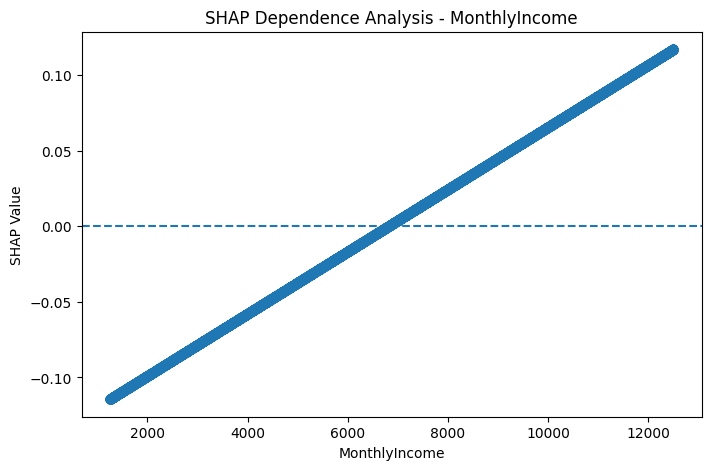

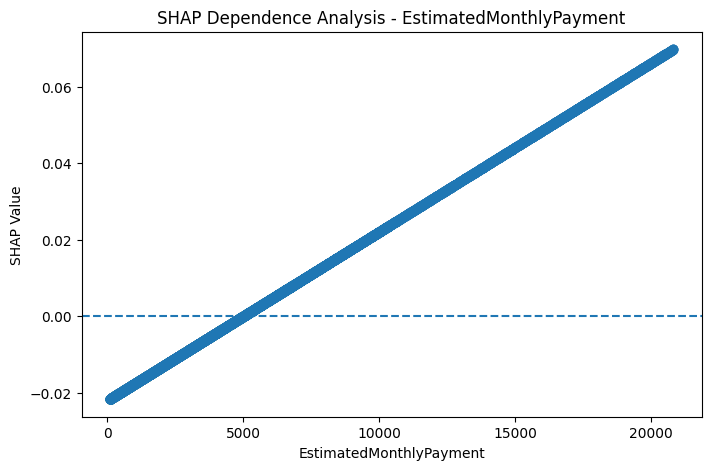

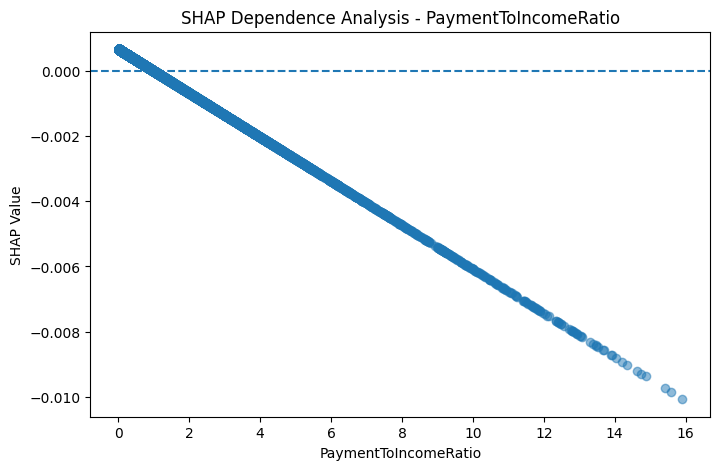

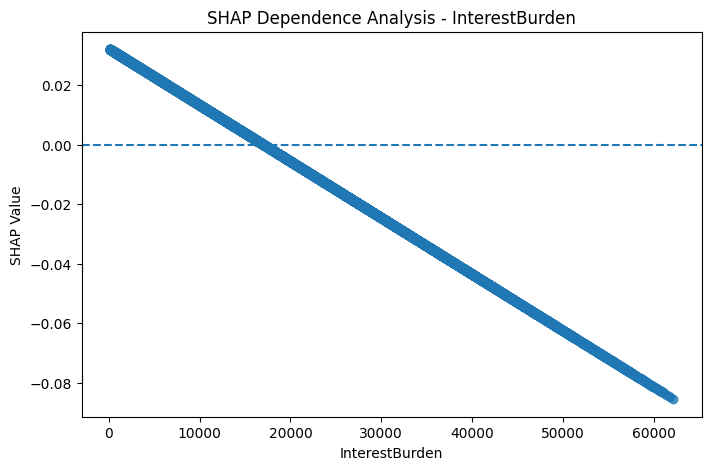

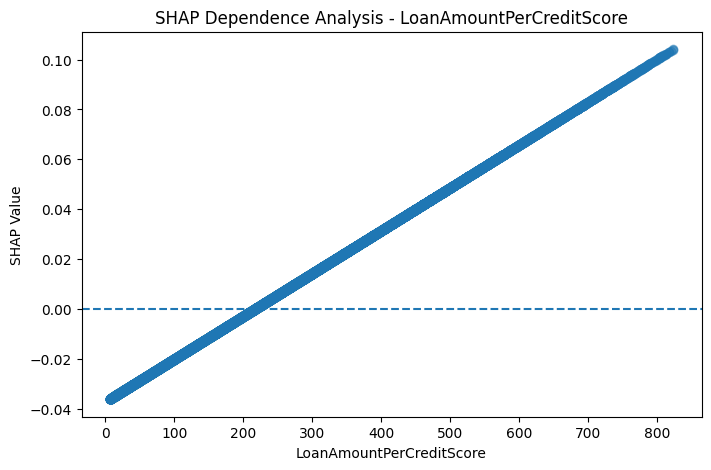

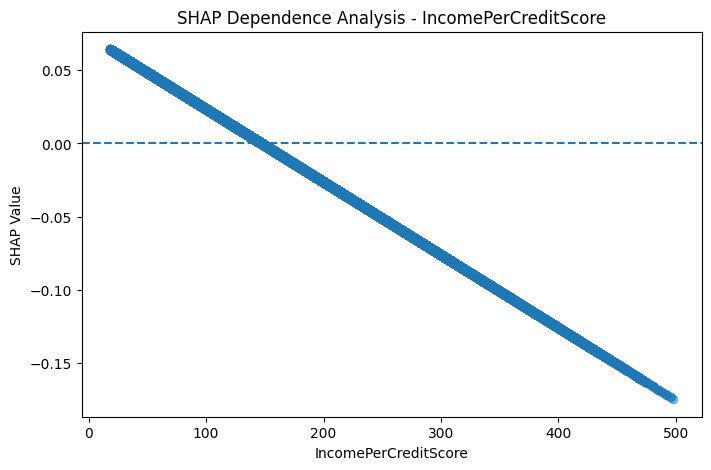

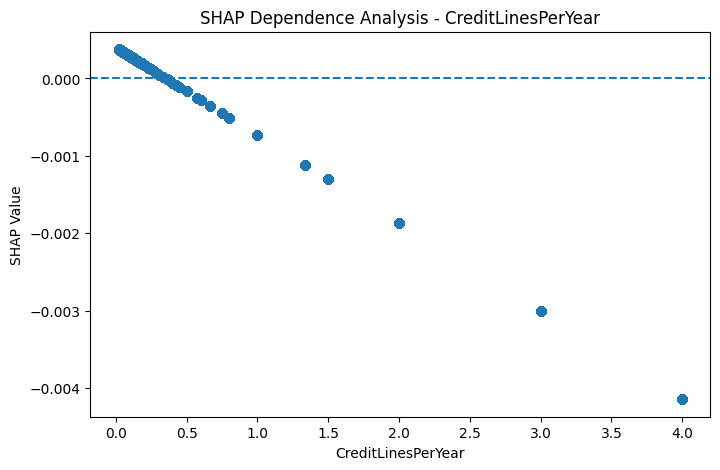

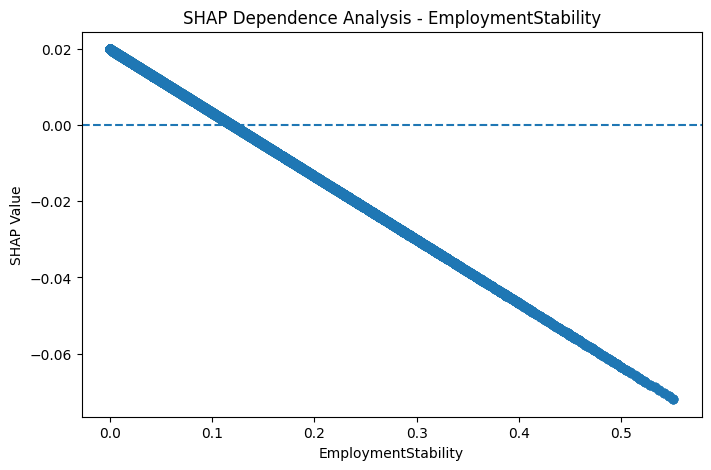

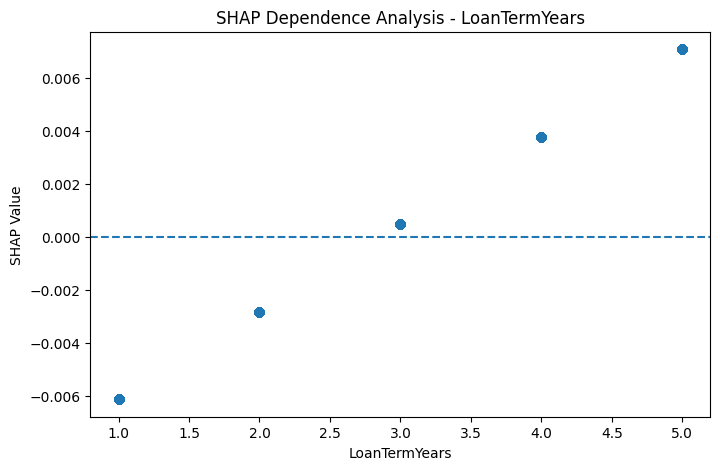

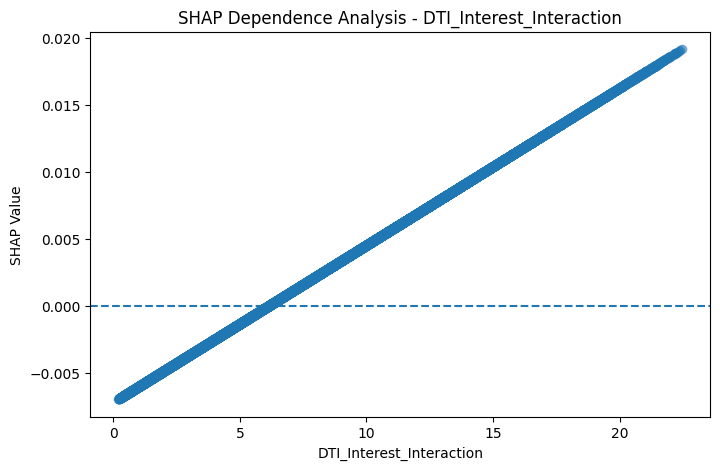

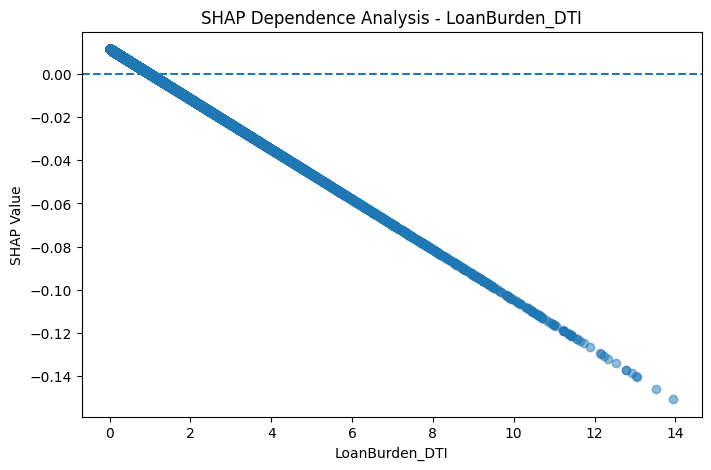

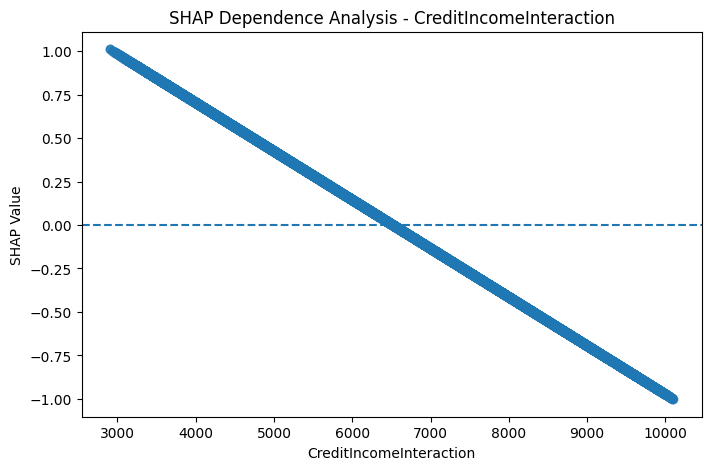

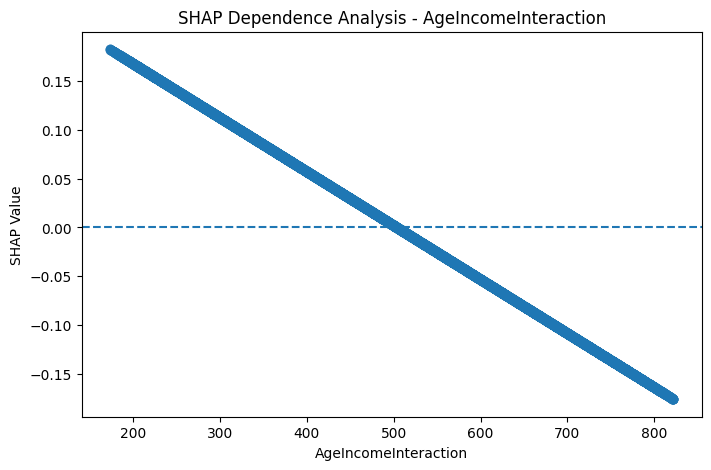

In [ ]:
for feature in continuous_features:

    transformed_feature = f"num__{feature}"

    if transformed_feature not in feature_names:
        print(f"{feature} not found.")
        continue

    index = list(feature_names).index(
        transformed_feature
    )

    plt.figure(figsize=(8, 5))

    plt.scatter(
        X_test[feature],
        shap_values[:, index],
        alpha=0.5
    )

    plt.axhline(
        y=0,
        linestyle="--"
    )

    plt.xlabel(feature)
    plt.ylabel("SHAP Value")

    plt.title(
        f"SHAP Dependence Analysis - {feature}"
    )

    plt.show()

# Save the continuous SHAP results


In [ ]:
continuous_shap_df.to_csv(
    "continuous_variable_shap_analysis.csv",
    index=False
)

print(
    "Continuous SHAP analysis saved successfully."
)

Continuous SHAP analysis saved successfully.


# Individual borrower explanation

In [ ]:
# Select one borrower from the test set
sample_index = 0

# Original borrower data
borrower = X_test.iloc[[sample_index]]

# Prediction using the complete preprocessing + model pipeline
borrower_prediction = best_model.predict(borrower)[0]

# Probability of default
borrower_probability = best_model.predict_proba(
    borrower
)[0, 1]

print("Individual Borrower Explanation")
print("=" * 50)

print("Predicted class:", borrower_prediction)
print(f"Probability of default: {borrower_probability:.2%}")

print("\nActual class:")

if y_test.iloc[sample_index] == 1:
    print("Default")
else:
    print("Non-Default")

Individual Borrower Explanation
Predicted class: 0
Probability of default: 19.86%

Actual class:
Non-Default


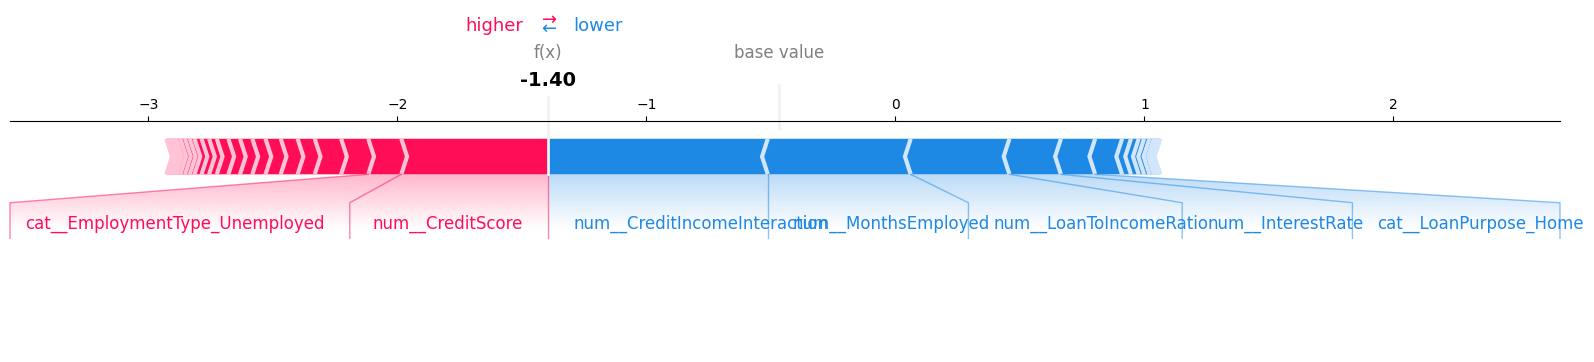

<Figure size 640x480 with 0 Axes>

In [ ]:
# SHAP EXPLANATION FOR THE SAME BORROWER

sample_features = X_test_transformed[sample_index]

sample_shap = shap_default[sample_index]

expected_value = explainer.expected_value

if isinstance(expected_value, (list, np.ndarray)):
    expected_value = expected_value[1]

shap.force_plot(
    expected_value,
    sample_shap,
    feature_names=feature_names,
    matplotlib=True
)

plt.tight_layout()
plt.show()

In [ ]:
#  TRANSFORM BORROWER FOR SHAP


preprocessor_fitted = best_model.named_steps["preprocessor"]

borrower_transformed = preprocessor_fitted.transform(
    borrower
)

# Convert sparse matrix to dense array if required
if hasattr(borrower_transformed, "toarray"):
    borrower_transformed = borrower_transformed.toarray()

# Get transformed feature names
feature_names = (
    preprocessor_fitted
    .get_feature_names_out()
)

print(
    "Borrower transformed shape:",
    borrower_transformed.shape
)

print(
    "Number of feature names:",
    len(feature_names)
)

Borrower transformed shape: (1, 45)
Number of feature names: 45


In [ ]:
# Create the individual explanation
borrower_shap_values = explainer.shap_values(
    borrower_transformed
)

# Handle different SHAP output formats
if isinstance(borrower_shap_values, list):
    borrower_shap_values = borrower_shap_values[1]

borrower_shap_values = np.asarray(
    borrower_shap_values
)

print(
    "Borrower SHAP shape:",
    borrower_shap_values.shape
)

Borrower SHAP shape: (1, 45)


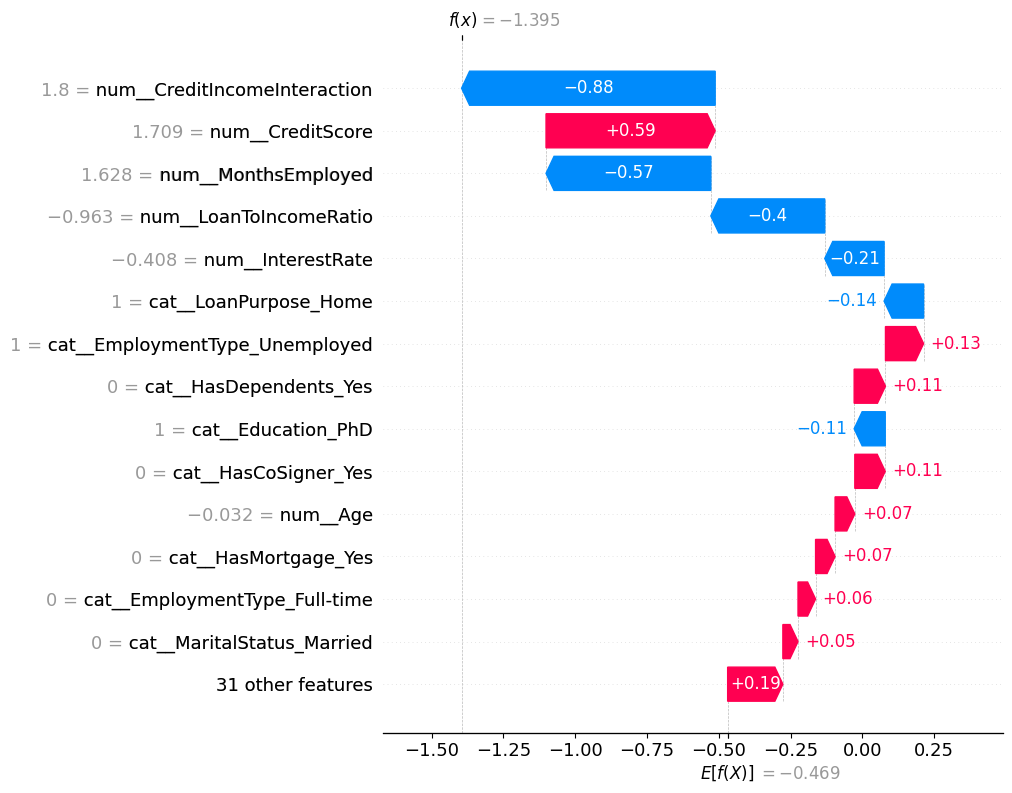

In [ ]:
# Create the SHAP waterfall plot
expected_value = explainer.expected_value

if isinstance(expected_value, (list, np.ndarray)):
    expected_value = np.asarray(expected_value).flatten()[0]

shap.waterfall_plot(
    shap.Explanation(
        values=borrower_shap_values[0],
        base_values=expected_value,
        data=borrower_transformed[0],
        feature_names=feature_names
    ),
    max_display=15
)